# 05 — Random Forest

Deuxième modèle : une forêt aléatoire, pour capter des seuils et interactions entre variables. **Il ne s’agit pas de boosting.** Exécuter d’abord le notebook 04 ; les données et partitions de référence seront vérifiées.

Chaque notebook compare son modèle à la même baseline. Les fonctions sont partagées dans `src/modeling.py` : on ne duplique pas les algorithmes.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "modeling.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "modeling.py").exists():
    raise RuntimeError("Lancer depuis la racine ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from hashlib import sha256
import numpy as np
import pandas as pd
from IPython.display import display
from src.data import export_table, table_path
from src.modeling import (DATA_PATH, MODEL_DIR, BINARY, NOMINAL, SCORES, EXCLUDED,
    load_model_data, make_split, build_pipelines, select_models, evaluate_test,
    transformed_features, save_artifacts, verify_reference_split)
from src.plots import plot_model_comparison
excel_hashes = {p: sha256(p.read_bytes()).hexdigest() for p in (ROOT / "data").rglob("*.xlsx")}
X, y, source_rows, groups, quantitative = load_model_data()
print(f"{len(X)} salariés ; {X.shape[1]} variables explicatives ; {int(y.sum())} départs")
print(DATA_PATH.relative_to(ROOT))

1518 salariés ; 30 variables explicatives ; 248 départs
data/variantes/01_baseline.xlsx


## 1. Charger sans corriger les données
La variante 01 conserve les 1 518 lignes et les valeurs initiales. Les scores hors dictionnaire et incohérences d’ancienneté restent inchangés dans cette expérience. Aucune suppression, imputation ou valeur plafonnée. Les valeurs manquantes et codes binaires inattendus déclenchent un diagnostic.

La cible Attrition vaut No=0, Yes=1 ; `depart`, Attrition et les quatre colonnes exclues ne sont jamais dans X. La ligne Excel source reste dans un repère séparé.

In [2]:
display(export_table(groups, "05_groupes_variables"))
display(groups.groupby("groupe").size().rename("nombre").to_frame())
print("Quantitatives :", quantitative)
print("Binaires :", BINARY)
assert not set(EXCLUDED + ["ligne_excel_source"]).intersection(X.columns)
assert len(X) == len(y) == len(source_rows)
print("Valeurs manquantes :", int(X.isna().sum().sum()))

,variable,groupe
0,Gender,binaire
1,OverTime,binaire
2,BusinessTravel,nominale
3,Department,nominale
4,EducationField,nominale
5,JobRole,nominale
6,MaritalStatus,nominale
7,Education,score_ordonne
8,EnvironmentSatisfaction,score_ordonne
9,JobInvolvement,score_ordonne


,nombre
groupe,
binaire,2
nominale,5
quantitative,14
score_ordonne,9


Quantitatives : ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Binaires : {'Gender': {'Male': 0, 'Female': 1}, 'OverTime': {'No': 0, 'Yes': 1}}
Valeurs manquantes : 0


## 2. Réserver le test et définir les plis
Le split stratifié 80/20 utilise `random_state=42`. Cinq plis stratifiés mélangés sont définis sur les 80 % d’entraînement uniquement. La fonction commune reconstruit exactement les mêmes indices dans 04 et 05. Le 05 compare ensuite tous les indices ordonnés et l’empreinte du fichier aux sauvegardes du 04 ; une différence interrompt l’exécution.

Les proportions de départ sont observées dans le fichier, sans annualisation.

In [3]:
X_train, X_test, y_train, y_test, folds, split_rows = make_split(X, y, source_rows)
reference_metadata = verify_reference_split(split_rows)
print("Même source, même split et mêmes plis que le notebook 04.")
assert set(X_train.index).isdisjoint(X_test.index)
repartition = pd.DataFrame({"partie": ["entraînement", "test"],
    "effectif": [len(y_train), len(y_test)], "departs": [int(y_train.sum()), int(y_test.sum())],
    "proportion_depart": [y_train.mean(), y_test.mean()]})
display(export_table(repartition, "05_repartition_split"))
display(export_table(pd.DataFrame([{"pli": i, "apprentissage": len(a), "validation": len(v),
    "departs_validation": int(y_train.iloc[v].sum())} for i, (a,v) in enumerate(folds)]), "05_repartition_plis"))

Même source, même split et mêmes plis que le notebook 04.


,partie,effectif,departs,proportion_depart
0,entraînement,1214,198,0.163097
1,test,304,50,0.164474


,pli,apprentissage,validation,departs_validation
0,0,971,243,39
1,1,971,243,40
2,2,971,243,40
3,3,971,243,40
4,4,972,242,39


## 3. Comprendre Random Forest
Un arbre pose une succession de questions : par exemple, la distance dépasse-t-elle un seuil, puis le salarié fait-il des heures supplémentaires ? Les feuilles regroupent des observations et fournissent une probabilité de départ.

La forêt entraîne **200 arbres séparément**, avec des échantillons de salariés tirés avec remise (bootstrap) et des sous-ensembles aléatoires de variables à chaque séparation. La moyenne des probabilités des arbres donne la prédiction finale. Les arbres peuvent être calculés en parallèle ; ils ne corrigent pas successivement leurs erreurs.

Cela permet de représenter des seuils et interactions sans les écrire à l’avance. En contrepartie, la lecture est moins simple qu’une somme de coefficients et une forêt trop flexible peut surapprendre.

**Différence avec le boosting :** le boosting ajoute des arbres successifs pour améliorer les erreurs du modèle courant. Ce notebook utilise une forêt aléatoire, pas un algorithme de boosting.

## 4. Préparer les variables dans le pipeline
- **Binaires** : même encodage 0/1 que dans le 04.
- **Nominales** : one-hot avec `drop=None` et `handle_unknown="ignore"`.
- **Scores et quantitatives** : numériques inchangés, sans standardisation. Un arbre cherche des seuils ; centrer/réduire n’est pas nécessaire ici.

**Hypothèse importante :** le modèle utilise l’ordre numérique des scores, y compris les codes hors dictionnaire conservés. Contrairement au 04, il peut couper entre deux codes. Cette convention n’établit pas leur validité métier.

L’encodage est appris à l’intérieur de chaque pli, jamais sur les données de validation ou de test.

In [4]:
pipeline = build_pipelines(quantitative)["RandomForest"]
display(pipeline)

Pipeline(steps=[('preparation',
                 ColumnTransformer(transformers=[('binaires',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function encode_binary at 0x11ce1fdc0>),
                                                  ['Gender', 'OverTime']),
                                                 ('categories',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'JobRole',
                                                   'MaritalStatus']),
                                                 ('scores'...
                                                  'passthrough',
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'HourlyRate',
                                                   'MonthlyIncome',
                                                   'MonthlyRate',
                                                   'NumCompaniesWorked',
                                                   'PercentSalaryHike',
                                                   'TotalWorkingYears',
                                                   'TrainingTimesLastYear',
                                                   'YearsAtCompany',
                                                   'YearsInCurrentRole',
                                                   'YearsSinceLastPromotion',
                                                   'YearsWithCurrManager'])])),
                ('modele',
                 RandomForestClassifier(n_estimators=200, n_jobs=1,
                                        random_state=42))])

## 5. Sélectionner les paramètres uniquement sur l’entraînement
8 configurations : max_depth ∈ {6, None}, min_samples_leaf ∈ {2, 8}, class_weight ∈ {None, balanced}, avec 200 arbres. Une profondeur limitée ou un minimum de salariés par feuille plus élevé freinent le surapprentissage.

GridSearchCV compare les configurations sur les cinq plis et sélectionne la meilleure **average precision** (AP). Puis le pipeline retenu est réajusté sur tout l’entraînement. La baseline `DummyClassifier(strategy="prior")` prédit toujours la proportion de départs apprise ; elle utilise les mêmes plis.

Les moyennes et écarts-types CV sont exportés. Ce ne sont pas des intervalles de confiance ; la sélection des paramètres peut rendre ces scores optimistes, car la validation n’est pas imbriquée.

In [5]:
searches, cv_results = select_models(X_train, y_train, folds, quantitative,
    model_names=["RandomForest", "Baseline"])
display(export_table(cv_results, "05_validation_croisee"))
for name, search in searches.items():
    print(name, ":", search.best_params_)
    export_table(pd.DataFrame(search.cv_results_), f"05_recherche_{name}")
    assert search.cv is folds

Validation croisée : RandomForest


Validation croisée : Baseline


,modele,evaluation,seuil,parametres,average_precision,average_precision_ecart_type,roc_auc,roc_auc_ecart_type,precision,precision_ecart_type,recall,recall_ecart_type,f1,f1_ecart_type
0,RandomForest,CV_entrainement,0.5,"{""modele__class_weight"": null, ""modele__max_de...",0.558710,0.100385,0.799533,0.061318,0.781984,0.203844,0.166667,0.040609,0.274361,0.067214
1,Baseline,CV_entrainement,0.5,{},0.163096,0.001865,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


RandomForest : {'modele__class_weight': None, 'modele__max_depth': None, 'modele__min_samples_leaf': 2}
Baseline : {}


## 6. Évaluer une seule fois sur le test réservé
Le seuil est fixé à **0,5**, sans optimisation à partir du test. Les probabilités sont calculées une seule fois et réutilisées pour toutes les métriques et figures.

- **Average precision** : résume la courbe précision-rappel ; la baseline correspond à la prévalence.
- **ROC-AUC** : qualité de classement des départs par rapport aux non-départs, sur tous les seuils.
- **Précision** : parmi les départs prédits, combien sont observés ?
- **Rappel** : parmi les départs observés, combien sont détectés ?
- **F1** : moyenne harmonique de précision et rappel.

Dans la matrice, une ligne représente la classe observée et une colonne la classe prédite. Un faux négatif est un départ manqué ; un faux positif est un départ prédit non observé. Une AP élevée ne garantit pas un bon rappel au seuil 0,5.

,modele,evaluation,seuil,parametres,average_precision,average_precision_ecart_type,roc_auc,roc_auc_ecart_type,precision,precision_ecart_type,recall,recall_ecart_type,f1,f1_ecart_type,vrais_negatifs,faux_positifs,faux_negatifs,vrais_positifs
0,RandomForest,CV_entrainement,0.5,"{""modele__class_weight"": null, ""modele__max_de...",0.558710,0.100385,0.799533,0.061318,0.781984,0.203844,0.166667,0.040609,0.274361,0.067214,NaN,NaN,NaN,NaN
1,Baseline,CV_entrainement,0.5,{},0.163096,0.001865,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
2,RandomForest,test_reserve,0.5,NaN,0.506820,NaN,0.818819,NaN,0.857143,NaN,0.240000,NaN,0.375000,NaN,252.0,2.0,38.0,12.0
3,Baseline,test_reserve,0.5,NaN,0.164474,NaN,0.500000,NaN,0.000000,NaN,0.000000,NaN,0.000000,NaN,254.0,0.0,50.0,0.0


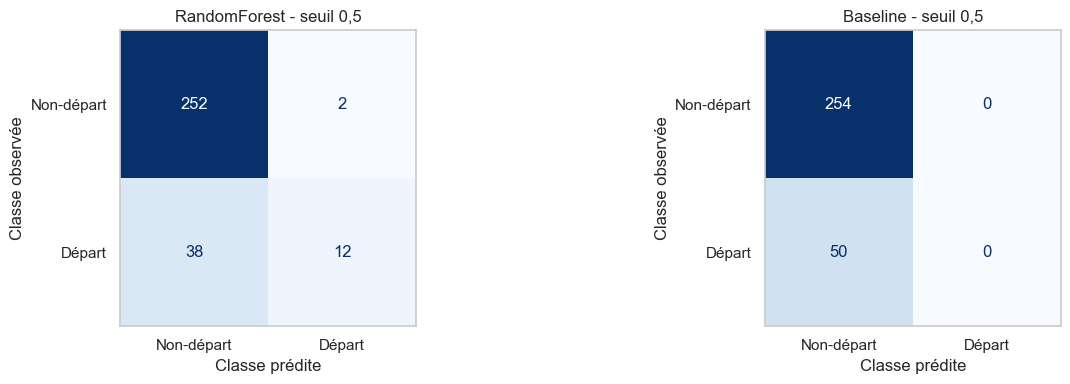

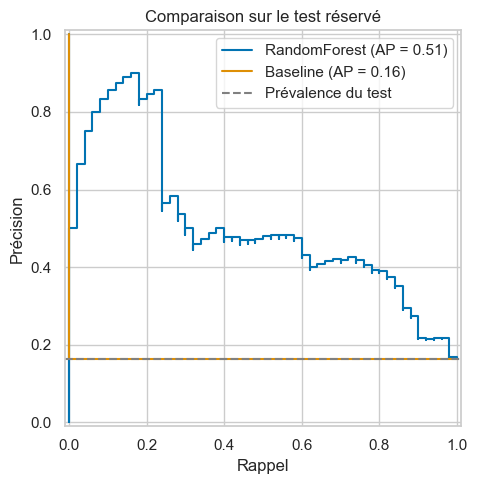

Au seuil 0,5 : 12 départs détectés sur 50 (rappel 24.0%) ; précision 85.7%.


In [6]:
test_results, predictions = evaluate_test(searches, X_test, y_test)
comparison = pd.concat([cv_results, test_results], ignore_index=True)
display(export_table(comparison, "05_comparaison_performances"))
export_table(test_results, "05_evaluation")
plot_model_comparison(y_test, predictions, prefix="05")
result = test_results.loc[test_results.modele.eq("RandomForest")].iloc[0]
print(f"Au seuil 0,5 : {int(result.vrais_positifs)} départs détectés sur {int(y_test.sum())} "
      f"(rappel {result.recall:.1%}) ; précision {result.precision:.1%}.")

## 7. Sauvegarder le modèle et vérifier la reproductibilité
Le pipeline sauvegardé inclut son prétraitement. Les indices, plis, paramètres, versions et empreinte Excel sont enregistrés avec le préfixe 05. Les sauvegardes sont relues sur un échantillon d’entraînement, sans réévaluer le test.

In [7]:
feature_names = transformed_features(searches)
display(export_table(feature_names, "05_variables_transformees"))
metadata = save_artifacts(searches, split_rows, prefix="05")
import joblib
for name, search in searches.items():
    restored = joblib.load(MODEL_DIR / f"05_{name}.joblib")
    np.testing.assert_allclose(restored.predict_proba(X_train.iloc[:8]),
        search.best_estimator_.predict_proba(X_train.iloc[:8]))
for p, fingerprint in excel_hashes.items():
    assert sha256(p.read_bytes()).hexdigest() == fingerprint, f"Excel modifié : {p}"
print("Pipelines sauvegardés ; toutes les sources Excel sont inchangées.")

,modele,position,variable_transformee
0,RandomForest,0,binaires__Gender
1,RandomForest,1,binaires__OverTime
2,RandomForest,2,categories__BusinessTravel_Non-Travel
3,RandomForest,3,categories__BusinessTravel_Travel_Frequently
4,RandomForest,4,categories__BusinessTravel_Travel_Rarely
5,RandomForest,5,categories__Department_Human Resources
6,RandomForest,6,categories__Department_Research & Development
7,RandomForest,7,categories__Department_Sales
8,RandomForest,8,categories__EducationField_Human Resources
9,RandomForest,9,categories__EducationField_Life Sciences


Pipelines sauvegardés ; toutes les sources Excel sont inchangées.


## 8. Comparer les deux méthodes
| Aspect | Régression logistique (04) | Random Forest (05) |
|---|---|---|
| Fonctionnement | Somme de contributions, puis fonction logistique | Moyenne des probabilités de nombreux arbres |
| Relations | Additives sur le log des cotes, sans interactions automatiques | Seuils et interactions appris automatiquement |
| Scores | Modalités one-hot indépendantes | Valeurs numériques ordonnées conservées |
| Standardisation | Quantitatives uniquement | Aucune |
| Lecture | Coefficients accessibles, sous réserve de l’encodage et de la pénalisation | Plus difficile de résumer toutes les règles |
| Régularisation | L2, contrôlée par C | Profondeur, taille des feuilles et moyenne des arbres |

Les performances ci-dessous proviennent des **mêmes lignes, du même split et des mêmes plis vérifiés**. Les représentations des scores diffèrent aussi : la comparaison porte sur deux pipelines complets, pas uniquement sur les algorithmes. Elle ne signifie pas qu’une méthode est supérieure dans tous les contextes. Ne pas réajuster les modèles ni choisir le seuil après lecture du test.

In [8]:
verify_reference_split(split_rows)
logistic_results = pd.read_csv(table_path("04_comparaison_performances"))
assert set(logistic_results.modele) == {"Logistique", "Baseline"}, "Réexécuter le nouveau notebook 04."
combined = pd.concat([logistic_results.loc[logistic_results.modele.eq("Logistique")], comparison], ignore_index=True)
columns = ["modele", "evaluation", "average_precision", "roc_auc", "precision", "recall", "f1", "seuil"]
display(export_table(combined, "05_comparaison_modeles" )[columns])
for name, model_result in combined.loc[combined.evaluation.eq("test_reserve")].set_index("modele").iterrows():
    print(f"{name} — AP test : {model_result.average_precision:.3f}, rappel : {model_result.recall:.1%}")

,modele,evaluation,average_precision,roc_auc,precision,recall,f1,seuil
0,Logistique,CV_entrainement,0.650393,0.840337,0.850198,0.318462,0.461932,0.5
1,Logistique,test_reserve,0.685237,0.868661,0.800000,0.320000,0.457143,0.5
2,RandomForest,CV_entrainement,0.558710,0.799533,0.781984,0.166667,0.274361,0.5
3,Baseline,CV_entrainement,0.163096,0.500000,0.000000,0.000000,0.000000,0.5
4,RandomForest,test_reserve,0.506820,0.818819,0.857143,0.240000,0.375000,0.5
5,Baseline,test_reserve,0.164474,0.500000,0.000000,0.000000,0.000000,0.5


Logistique — AP test : 0.685, rappel : 32.0%
RandomForest — AP test : 0.507, rappel : 24.0%
Baseline — AP test : 0.164, rappel : 0.0%


## Limites à retenir
Les probabilités, en particulier avec une pondération des classes, ne sont pas automatiquement bien calibrées. Un seul split et peu de départs rendent les estimations incertaines. Les anomalies conservées peuvent influencer les modèles.

La chronologie des variables est inconnue : un split correct ne suffit pas à éliminer une possible fuite temporelle. Les modèles décrivent des associations prédictives, pas les causes des départs, une discrimination ou les effets attendus d’une action RH. Aucun pays ne valide la généralisation à l’Afrique ; l’absentéisme n’est pas mesurable ici.

Le guide PDF décrit un protocole antérieur ; les anciens exports archivés ont été supprimés. Les résultats de ce parcours sont ceux des notebooks 04 et 05 actuels.